## Analytics Firm Clients: Customer Reviews Analysis

### Part 1: Natural Language Processing (NLP)

In [1]:
! pip install seaborn
! pip install nltk

In [6]:
# Part 1: NLP 


# 1.1 Import libraries

# 1. Import libraries for data handling
import numpy as np
import pandas as pd

# 2. Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Import libraries for text cleaning
import re
import string
import html

# 4. Import libraries for Natural Language Processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.util import ngrams

# 5. Import Counter for word frequency analysis
from collections import Counter

# 6. Download required NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

# 7. Set random seed for reproducibility
np.random.seed(42)

# 8. Set visualization style
sns.set_theme(style='whitegrid')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\kevin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\kevin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kevin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\kevin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [ ]:
# 1.2. Data loading and understanding

# 1. Load the dataset from the datasets folder
df = pd.read_csv("data/amazon_reviews_lab.csv")

print("Dataset loaded successfully!")

# 2. Display the shape of the dataset
print("Dataset shape:", df.shape)

# 3. Display the first few rows of the dataset
display(df.head())

Dataset loaded successfully!
Dataset shape: (997, 9)


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [11]:
# 4. Inspect column names and data types
print("\nDataset Information:")
df.info()

# 5. Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 6. Check for duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# 7. Examine the distribution of customer ratings
print("\nRating Distribution:")
print(df['rating'].value_counts().sort_index())

# 8. Examine the distribution of sentiment labels
print("\nSentiment Distribution:")
print(df['sentiment_label'].value_counts())

# 9. Generate summary statistics
display(df.describe(include='all'))


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           997 non-null    str    
 1   rating               997 non-null    int64  
 2   review_text          997 non-null    str    
 3   review_summary       997 non-null    str    
 4   review_time_raw      997 non-null    str    
 5   unix_review_time     997 non-null    float64
 6   timestamp            997 non-null    str    
 7   sentiment_label      997 non-null    str    
 8   review_length_words  997 non-null    int64  
dtypes: float64(1), int64(2), str(6)
memory usage: 70.2 KB

Missing Values:
product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
dtype: int64

Duplicate Records:
0

,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
count,997,997.000000,997,997,997,9.970000e+02,997,997,997.000000
unique,40,NaN,997,938,722,NaN,722,3,NaN
top,0972683275,NaN,This film is definitely not for anyone who is ...,Works great,"09 18, 2013",NaN,2013-09-18,positive,NaN
freq,218,NaN,1,6,6,NaN,6,768,NaN
mean,NaN,4.129388,NaN,NaN,NaN,1.344766e+09,NaN,NaN,146.374122
std,NaN,1.280181,NaN,NaN,NaN,4.411420e+07,NaN,NaN,216.126770
min,NaN,1.000000,NaN,NaN,NaN,9.580896e+08,NaN,NaN,5.000000
25%,NaN,4.000000,NaN,NaN,NaN,1.311898e+09,NaN,NaN,32.000000
50%,NaN,5.000000,NaN,NaN,NaN,1.356048e+09,NaN,NaN,67.000000
75%,NaN,5.000000,NaN,NaN,NaN,1.379462e+09,NaN,NaN,165.000000


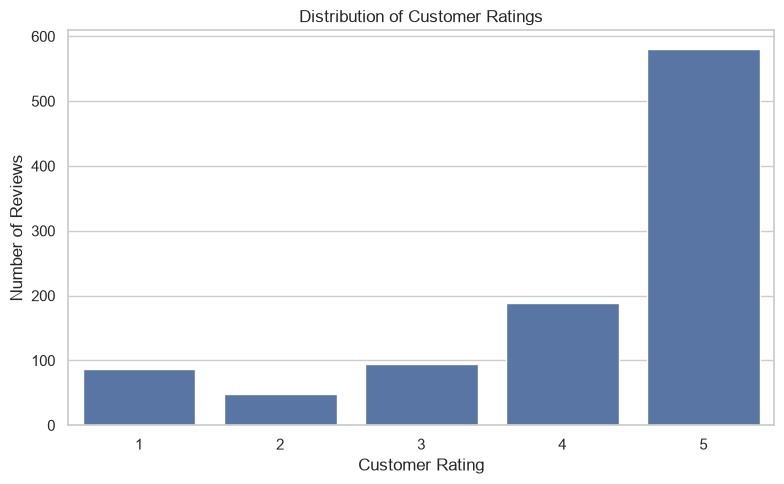

In [12]:
# 1.3. Exploratory Data Analysis - Rating Distribution

# 1. Create a figure
plt.figure(figsize=(8, 5))

# 2. Plot the frequency of each rating
sns.countplot(
    data=df,
    x='rating',
    order=sorted(df['rating'].dropna().unique())
)

# 3. Add descriptive labels
plt.title('Distribution of Customer Ratings')
plt.xlabel('Customer Rating')
plt.ylabel('Number of Reviews')

# 4. Display the visualization
plt.tight_layout()
plt.show()

In [13]:
# 1.4. Text Preprocessing Setup


# 1. Load common English stopwords
stop_words = set(stopwords.words('english'))

# 2. Initialize the WordNet lemmatizer
lemmatizer = WordNetLemmatizer()

# 3. Preserve negation words that may indicate sentiment
stop_words = stop_words - {
    'no', 'not', 'nor'
}

# 4. Inspect a few stopwords
print("Sample Stopwords:")
print(list(sorted(stop_words))[:20])

Sample Stopwords:
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']


In [14]:
# 1.5. Text Preprocessing Function

# Purpose:
# Create a reusable function that:
# 1. Converts text to lowercase
# 2. Removes URLs
# 3. Removes punctuation
# 4. Tokenizes the text
# 5. Keeps alphabetic tokens
# 6. Removes stopwords
# 7. Lemmatizes words
# 8. Returns cleaned tokens


def preprocess_text(text):

    # Step 1: Handle missing or non-text values
    if pd.isna(text):
        return []

    # Step 2: Convert text to lowercase
    text = str(text).lower()

    # Step 3: Decode HTML entities
    text = html.unescape(text)

    # Step 4: Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Step 5: Remove punctuation
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # Step 6: Tokenize the text into individual words
    tokens = word_tokenize(text)

    # Step 7: Keep alphabetic tokens only
    tokens = [
        word for word in tokens
        if word.isalpha()
    ]

    # Step 8: Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Step 9: Lemmatize the remaining words
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # Step 10: Return cleaned tokens
    return tokens


# Test the preprocessing function
sample_review = df['review_text'].dropna().iloc[0]

print("Original Review:")
print(sample_review[:300])

print("\nProcessed Tokens:")
print(preprocess_text(sample_review)[:30])

Original Review:
This film is definitely not for anyone who is especially fond of the independent, delightfully manipulative and clever boy who was the brain child of Samuel Clemens's classic.As one example, the book has great fun with the scenes involving Aunt Polly, a simple minded soul who thinks herself quite cl

Processed Tokens:
['film', 'definitely', 'not', 'anyone', 'especially', 'fond', 'independent', 'delightfully', 'manipulative', 'clever', 'boy', 'brain', 'child', 'samuel', 'clemens', 'classicas', 'one', 'example', 'book', 'great', 'fun', 'scene', 'involving', 'aunt', 'polly', 'simple', 'minded', 'soul', 'think', 'quite']


In [15]:
# 1.6. Apply Text Preprocessing

# 1. Process all customer reviews
df['processed_tokens'] = df['review_text'].apply(
    preprocess_text
)

# 2. Convert cleaned tokens back into text
df['cleaned_text'] = df['processed_tokens'].apply(
    lambda tokens: ' '.join(tokens)
)

# 3. Compare original and cleaned reviews
display(
    df[['review_text', 'processed_tokens', 'cleaned_text']]
    .head()
)

# 4. Check for reviews with no remaining tokens
print(
    "Empty Processed Reviews:",
    (df['processed_tokens'].apply(len) == 0).sum()
)

,review_text,processed_tokens,cleaned_text
0,This film is definitely not for anyone who is ...,"[film, definitely, not, anyone, especially, fo...",film definitely not anyone especially fond ind...
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac...",movie playing radio city music hall back day m...
2,I would love to buy this movie as I have been ...,"[would, love, buy, movie, hannibal, missouri, ...",would love buy movie hannibal missouri mark tw...
3,The advertisment for this DVD on Amazon was in...,"[advertisment, dvd, amazon, incorrect, ad, sta...",advertisment dvd amazon incorrect ad stated dv...
4,I bought some of these to try with a light usi...,"[bought, try, light, using, work, advertised, ...",bought try light using work advertised check m...


Empty Processed Reviews: 0


Top 20 Most Common Words:
nook: 1510
not: 1044
book: 913
one: 569
kindle: 561
screen: 496
like: 459
read: 454
work: 446
get: 424
great: 422
use: 420
tablet: 419
tv: 416
no: 387
device: 381
would: 378
good: 331
bn: 321
time: 318


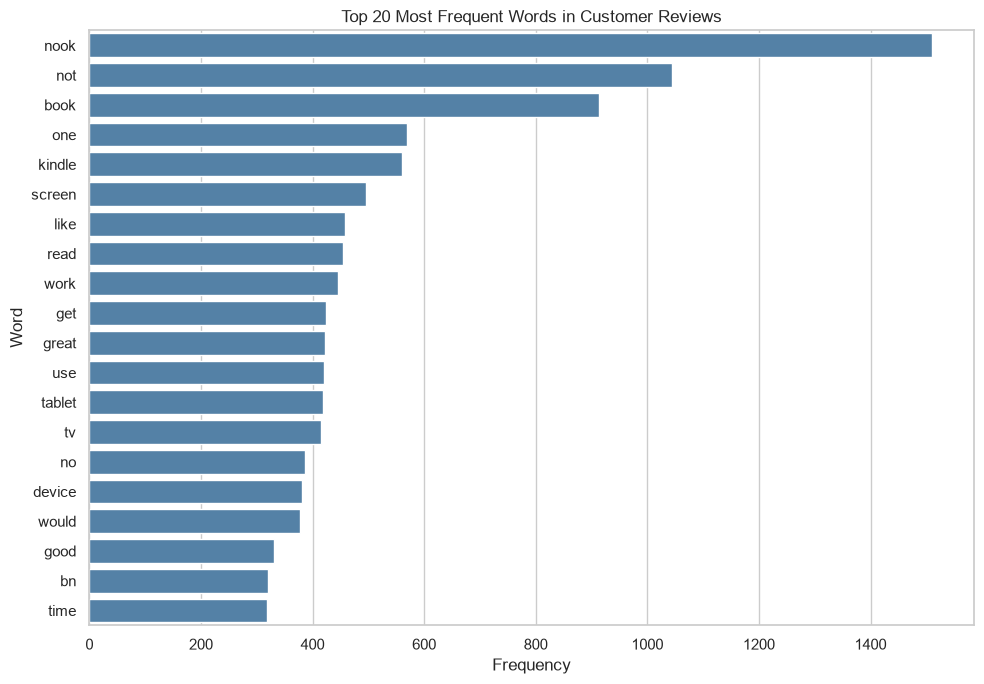

In [16]:
# 1.7. Word Frequency Analysis

# Purpose:
# Identify the words appearing most frequently
# across all customer reviews.


# 1. Combine tokens from all reviews
all_tokens = [
    token
    for document in df['processed_tokens']
    for token in document
]

# 2. Count how frequently each word appears
word_counts = Counter(all_tokens)

# 3. Identify the 20 most common words
top_20_words = word_counts.most_common(20)

# 4. Display results
print("Top 20 Most Common Words:")

for word, frequency in top_20_words:
    print(f"{word}: {frequency}")


# 1.8. Word Frequency Visualization


# 1. Convert frequency results into a DataFrame
word_freq_df = pd.DataFrame(
    top_20_words,
    columns=['Word', 'Frequency']
)

# 2. Create the visualization
plt.figure(figsize=(10, 7))

sns.barplot(
    data=word_freq_df,
    x='Frequency',
    y='Word',
    color='steelblue'
)

# 3. Add labels
plt.title('Top 20 Most Frequent Words in Customer Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')

# 4. Display the chart
plt.tight_layout()
plt.show()
